# 03 · Second look: LightGBM reviews the applicants the primary model rejects

## Where this notebook sits
```
04_feature_engineering ─► features_*.parquet ──────────────┐
05_encode_scale ────────► model_ready_*.parquet ─┐         │
                                                 ▼         ▼
model_building/01_primary_model   Stage 1: logistic regression decides first
model_building/02_lightgbm        LightGBM (+ calibration), trained on everyone
model_building/03_second_look     Stage 2: applicants REJECTED by stage 1 get a second look from LightGBM
```

## Read this first
**The pipeline.**
```
All applicants ─► Stage 1: primary model (logistic regression, notebook 01)
                    │  PD < 20% ─► APPROVE
                    │  PD ≥ 20% ─► REJECTED by stage 1
                    │                 └─► Stage 2: SECOND LOOK (LightGBM + calibration, notebook 02)
                    │                        PD < 20% ─► APPROVE ("rescued")
                    │                        PD ≥ 20% ─► DECLINE (final)
```
**What this notebook answers.**
1. How many rejected applicants does the second look rescue, who are they, and do they repay?
2. Does the two-stage pipeline beat the primary model alone on profit and fairness (inclusion gap)?
3. Is a general LightGBM good enough for the second look, or should it be a **specialist** trained only on rejected applicants?
4. How strict should the primary model be?

**Inputs:** stage-1 outputs from notebook 01, LightGBM predictions and settings from notebook 02 (`lightgbm/predictions/`, `lightgbm/params/`), and
`features_*.parquet` (to train the specialist). Run 01 and 02 first.
**Everything is scored on weeks 80-91**, which no model or setting was chosen on.

In [1]:
# Setup: libraries, paths, the week split and the shared scoring rules.

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from policy_metrics import CUTOFF, evaluate_decisions, evaluate_scores   # shared scoring rules (same folder)

warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")

ROOT = Path.cwd().parent.parent          # notebooks/model_building -> repo root
PROCESSED = ROOT / "data" / "processed"
ART = Path.cwd() / "artifacts"          # stage-1 outputs (notebook 01) and this notebook's outputs
ART.mkdir(exist_ok=True)
LGB_DIR = Path.cwd() / "lightgbm"       # LightGBM outputs (notebook 02)

SEED = 42
TUNE_START_WEEK = 68                     # weeks 0-67 train, 68-79 tune, 80-91 valid (scored once)
VALID_START_WEEK = 80

import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

## 1. Load stage-1 decisions and LightGBM predictions

In [2]:
# Join stage 1 (notebook 01) and LightGBM (notebook 02) predictions on case_id for the validation weeks.
s1_val = pd.read_parquet(ART / "primary_predictions_valid.parquet")
gbm_val = pd.read_parquet(LGB_DIR / "predictions" / "predictions_valid.parquet")[["case_id", "pd_lightgbm", "pd_lightgbm_calibrated"]]
val = s1_val.merge(gbm_val, on="case_id", validate="one_to_one")
assert len(val) == len(s1_val) == len(gbm_val), "notebooks 01 and 02 must cover the same applicants"

y, thin = val["target"].to_numpy(), val["thin_file"].to_numpy()
s1_approve = val["primary_approve"].to_numpy()
rejected = ~s1_approve
print(f"{len(val):,} applicants | stage 1 approves {s1_approve.mean():.1%}, rejects {rejected.mean():.1%} ({rejected.sum():,})")

130,441 applicants | stage 1 approves 60.5%, rejects 39.5% (51,551)


## 2. Optional: a specialist second-look model

The LightGBM from notebook 02 learned from **everyone**. The second look only ever sees applicants stage 1 rejected, a riskier
group with more thin-file people. A **specialist** learns only from that group:
- trained on stage-1-rejected applicants in weeks 0-67, with notebook 02's chosen settings and early stopping on rejected applicants in weeks 68-79
- calibrated per segment on rejected applicants in weeks 68-79 (same method as notebook 02)

**Decision rule, set before looking:** use the specialist only if, on weeks 80-91, it beats the general LightGBM by at least $0.3M
profit **and** does not widen the inclusion gap. Otherwise the general model is simpler and reused as-is.

In [3]:
# Train the specialist on the people stage 1 rejects (train weeks), stop and calibrate on rejected tune-week applicants.
feat_train = pd.read_parquet(PROCESSED / "features_train.parquet")
feat_test = pd.read_parquet(PROCESSED / "features_test.parquet")
params = json.load(open(LGB_DIR / "params" / "best_params.json"))["lightgbm"]["params"]

NOT_FEATURES = ["case_id", "target", "WEEK_NUM", "thin_file", "date_decision", "birth_259D"]
FEAT = [c for c in feat_train.columns if c not in NOT_FEATURES]
CATS = {c: sorted(feat_train[c].dropna().unique()) for c in FEAT if not pd.api.types.is_numeric_dtype(feat_train[c])}

def prepare(df):
    X = df[FEAT].copy()
    for c, cats in CATS.items():
        X[c] = pd.Categorical(X[c], categories=cats)
    return X

# Stage-1 routing for the training weeks comes from notebook 01.
s1_fit = pd.read_parquet(ART / "primary_predictions_fit.parquet")[["case_id", "primary_approve"]]
train = feat_train.merge(s1_fit, on="case_id", how="inner", validate="one_to_one")   # weeks 0-79 only
w = train["WEEK_NUM"].to_numpy()
rej_tr = (~train["primary_approve"].to_numpy()) & (w < TUNE_START_WEEK)
rej_tu = (~train["primary_approve"].to_numpy()) & (w >= TUNE_START_WEEK)
X_tr, X_tu = prepare(train[rej_tr]), prepare(train[rej_tu])
y_tr, y_tu = train.loc[rej_tr, "target"].to_numpy(), train.loc[rej_tu, "target"].to_numpy()

t = time.time()
d_tr = lgb.Dataset(X_tr, y_tr, params={"feature_pre_filter": False})
specialist = lgb.train(params, d_tr, num_boost_round=5000, valid_sets=[lgb.Dataset(X_tu, y_tu, reference=d_tr)],
                       callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"specialist: {rej_tr.sum():,} rejected training applicants, {specialist.best_iteration} trees, {time.time() - t:.0f}s")


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_calibration(p, yy, seg):
    return {s: LogisticRegression(C=1e6).fit(logit(p[seg == s]), yy[seg == s]) for s in (0, 1)}


def apply_calibration(cal, p, seg):
    out = p.copy()
    for s, m in cal.items():
        out[seg == s] = m.predict_proba(logit(p[seg == s]))[:, 1]
    return out


spec_cal = fit_calibration(specialist.predict(X_tu, num_iteration=specialist.best_iteration), y_tu,
                           train.loc[rej_tu, "thin_file"].to_numpy())

feat_val = feat_train.set_index("case_id").loc[val["case_id"]].reset_index()
p_spec_raw = specialist.predict(prepare(feat_val), num_iteration=specialist.best_iteration)
val["pd_specialist_calibrated"] = apply_calibration(spec_cal, p_spec_raw, thin)

specialist: 296,563 rejected training applicants, 354 trees, 7s


## 3. Compare the policies

| Policy | How it decides |
|---|---|
| **A. Primary only** | stage 1 alone: approve if logistic-regression PD < 20% |
| **B. Two-stage, LightGBM** | stage 1 approvals + rejected applicants with LightGBM PD < 20% |
| **C. Two-stage, LightGBM + calibration** | the same, with notebook 02's calibrated LightGBM (**the main design**) |
| **D. Two-stage, specialist** | the same, with the specialist trained on rejected applicants |
| E. LightGBM + calibration only | one stage, no primary model, for reference |

`Rescued` = applicants rejected by stage 1 but approved by the second look.

In [4]:
# Build each policy's approve/decline decisions and score them with the shared rules.
second_look = {
    "B. Two-stage, LightGBM": val["pd_lightgbm"].to_numpy(),
    "C. Two-stage, LightGBM + calibration": val["pd_lightgbm_calibrated"].to_numpy(),
    "D. Two-stage, specialist": val["pd_specialist_calibrated"].to_numpy(),
}
policies = {"A. Primary only": s1_approve}
rescued = {}
for name, p2 in second_look.items():
    rescued[name] = rejected & (p2 < CUTOFF)
    policies[name] = s1_approve | rescued[name]
policies["E. LightGBM + calibration only"] = val["pd_lightgbm_calibrated"].to_numpy() < CUTOFF

rows = {}
for name, approve in policies.items():
    r = evaluate_decisions(y, approve, thin)
    res = rescued.get(name)
    r["Rescued"] = res.sum() if res is not None else np.nan
    r["Rescued default %"] = y[res].mean() * 100 if res is not None else np.nan
    r["Rescued thin-file %"] = thin[res].mean() * 100 if res is not None else np.nan
    rows[name] = r
results = pd.DataFrame(rows).T
results.to_csv(ART / "second_look_results_valid.csv")
results[["Approval %", "Default % approved", "Profit $M", "Approved repayers thin %", "Inclusion gap pp",
         "Accuracy", "F1", "Rescued", "Rescued default %", "Rescued thin-file %"]].round(2)

,Approval %,Default % approved,Profit $M,Approved repayers thin %,Inclusion gap pp,Accuracy,F1,Rescued,Rescued default %,Rescued thin-file %
A. Primary only,60.48,8.32,92.17,40.16,37.94,0.68,0.43,NaN,NaN,NaN
"B. Two-stage, LightGBM",64.04,8.74,94.08,46.36,34.32,0.70,0.44,4649.0,15.90,48.35
"C. Two-stage, LightGBM + calibration",69.10,9.35,96.02,64.29,16.21,0.74,0.45,11239.0,16.58,80.35
"D. Two-stage, specialist",69.33,9.43,95.60,63.52,17.55,0.74,0.45,11541.0,17.03,75.92
E. LightGBM + calibration only,67.12,8.94,96.85,64.29,13.62,0.72,0.45,NaN,NaN,NaN


In [5]:
# Pre-set rule: keep the specialist only if it clearly beats the general calibrated LightGBM as the second look.
gen, spec = results.loc["C. Two-stage, LightGBM + calibration"], results.loc["D. Two-stage, specialist"]
USE_SPECIALIST = bool(spec["Profit $M"] - gen["Profit $M"] >= 0.3 and spec["Inclusion gap pp"] <= gen["Inclusion gap pp"])
MAIN = "D. Two-stage, specialist" if USE_SPECIALIST else "C. Two-stage, LightGBM + calibration"
print(f"specialist vs general: profit {spec['Profit $M'] - gen['Profit $M']:+.2f} $M, gap {spec['Inclusion gap pp'] - gen['Inclusion gap pp']:+.2f} pp")
print("second-look model used:", "specialist" if USE_SPECIALIST else "general LightGBM + calibration (simpler, no clear gain from a specialist)")

specialist vs general: profit -0.42 $M, gap +1.34 pp
second-look model used: general LightGBM + calibration (simpler, no clear gain from a specialist)


**What this shows:** the second look works. Compared with the primary model alone (A), the main design (C) rescues **11,239**
applicants, **80% of them thin-file**, who default only **16.6%** of the time (under the 20% break-even, so profitable). Profit rises
**$92.2M → $96.0M** and the inclusion gap falls **37.9 → 16.2 points**. Without calibration (B) the second look rescues far fewer
thin-file applicants (gap 34.3), so calibration is what makes it effective. The **specialist (D) didn't beat the general LightGBM**
(−$0.4M, gap +1.3), so the simpler general model is used.

## 4. The funnel: what happens to 100 applicants

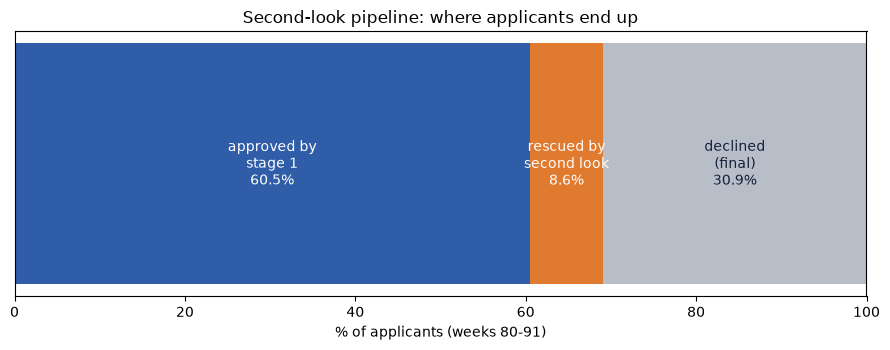

,applicants,per 100 applicants,actually default %,thin-file %
all applicants,130441,100.0,17.4,29.9
approved by stage 1,78890,60.5,8.3,17.4
rejected by stage 1,51551,39.5,31.2,49.1
rescued by second look,11239,8.6,16.6,80.3
declined (final),40312,30.9,35.3,40.4


In [6]:
# Funnel for the main design: stage 1 approvals, rescues, final declines, and how many of each actually repaid.
res_main = rescued[MAIN]
declined = rejected & ~res_main
funnel = pd.DataFrame({
    "applicants": [len(y), s1_approve.sum(), rejected.sum(), res_main.sum(), declined.sum()],
    "per 100 applicants": [100, s1_approve.mean() * 100, rejected.mean() * 100, res_main.mean() * 100, declined.mean() * 100],
    "actually default %": [y.mean() * 100, y[s1_approve].mean() * 100, y[rejected].mean() * 100, y[res_main].mean() * 100, y[declined].mean() * 100],
    "thin-file %": [thin.mean() * 100, thin[s1_approve].mean() * 100, thin[rejected].mean() * 100, thin[res_main].mean() * 100, thin[declined].mean() * 100],
}, index=["all applicants", "approved by stage 1", "rejected by stage 1", "  rescued by second look", "  declined (final)"])

fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ["approved by\nstage 1", "rescued by\nsecond look", "declined\n(final)"]
vals = [s1_approve.mean() * 100, res_main.mean() * 100, declined.mean() * 100]
ax.barh([0, 0, 0], vals, left=[0, vals[0], vals[0] + vals[1]], color=["#2F5DA8", "#E07A2E", "#B8BEC7"])
for left, v, lab in zip([0, vals[0], vals[0] + vals[1]], vals, labels):
    ax.text(left + v / 2, 0, f"{lab}\n{v:.1f}%", ha="center", va="center", color="white" if lab != labels[2] else "#14213D", fontsize=10)
ax.set(xlim=(0, 100), yticks=[], xlabel="% of applicants (weeks 80-91)", title="Second-look pipeline: where applicants end up")
plt.tight_layout(); plt.show()
funnel.round(1)

**What this shows:** of every 100 applicants, stage 1 approves ~60, the second look rescues ~9 more, and ~31 are finally declined.
The rescued group is 80% thin-file and defaults less than the 20% break-even; the finally declined group defaults at ~35%, so
those declines are justified.

## 5. Does the second look rank rejected applicants better than the primary model?

Within the rejected group only, AUC shows how well each model separates people who will repay from people who won't. If the
second look can't rank them better than stage 1, it isn't adding information.

In [7]:
# AUC computed only among stage-1-rejected applicants, overall and per segment.
def auc_within(p, mask):
    return roc_auc_score(y[mask], p[mask])

rank = {}
for name, p in [("Primary model", val["pd_primary"].to_numpy()), ("LightGBM", val["pd_lightgbm"].to_numpy()),
                ("Specialist", val["pd_specialist_calibrated"].to_numpy())]:
    rank[name] = {"AUC rejected": auc_within(p, rejected), "AUC rejected thin": auc_within(p, rejected & (thin == 1)),
                  "AUC rejected est": auc_within(p, rejected & (thin == 0))}
pd.DataFrame(rank).T.round(4)

,AUC rejected,AUC rejected thin,AUC rejected est
Primary model,0.6574,0.6472,0.6593
LightGBM,0.6681,0.6442,0.6788
Specialist,0.6741,0.6446,0.6790


**What this shows:** among rejected applicants, LightGBM separates future repayers from defaulters a little better than the primary
model (AUC 0.668 vs 0.657), mainly for established applicants. For thin-file rejected applicants all models rank equally (~0.645):
the second look's thin-file gain comes from **corrected probability levels (calibration)**, not better ranking.

## 6. The limit of a second look

A second look can only **add** approvals; it can't take back an approval stage 1 already gave. Some applicants the primary model
approves would be declined by LightGBM. If those are risky, the two-stage pipeline pays for them.

In [8]:
# Applicants stage 1 approves but the second-look model would decline: how many, how risky, and what they cost.
p_main = second_look[MAIN]
stuck = s1_approve & (p_main >= CUTOFF)
stuck_profit = (2_000 * (stuck & (y == 0)).sum() - 8_000 * (stuck & (y == 1)).sum()) / 1e6
print(f"approved by stage 1 but LightGBM would decline: {stuck.sum():,} applicants")
print(f"their actual default rate: {y[stuck].mean():.1%} (break-even is 20%)")
print(f"profit from them: ${stuck_profit:+.2f}M")

approved by stage 1 but LightGBM would decline: 2,581 applicants
their actual default rate: 23.2% (break-even is 20%)
profit from them: $-0.83M


**What this shows:** this is the cost of keeping the primary model's approvals. About 2,600 applicants approved by stage 1 would be
declined by LightGBM; they default at **23%**, above break-even, and cost about **$0.8M**. That's why the two-stage pipeline (C) is
slightly behind LightGBM alone (E): $96.0M vs $96.8M, gap 16.2 vs 13.6.

## 7. How strict should the primary model be?

The main design uses the same 20% cutoff in both stages. A **stricter** primary (a lower cutoff) approves only applicants it's very
confident about and sends more people to the second look. At a cutoff near 0, every decision is made by LightGBM.
This curve is **descriptive**: it is computed on weeks 80-91, so a cutoff picked from it would need confirming on other weeks (#14).

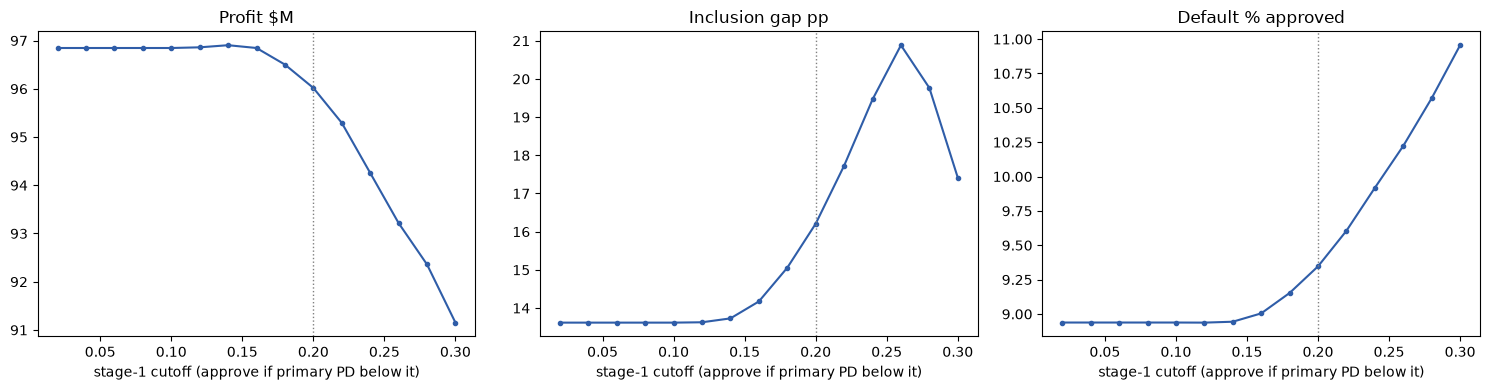

,% decided by stage 1,Approval %,Default % approved,Profit $M,Inclusion gap pp
stage-1 cutoff,,,,,
0.02,8.21,67.12,8.94,96.85,13.62
0.04,16.20,67.12,8.94,96.85,13.62
0.06,23.20,67.12,8.94,96.85,13.62
0.08,29.02,67.12,8.94,96.85,13.62
0.10,36.22,67.12,8.94,96.85,13.62
0.12,42.21,67.12,8.94,96.86,13.63
0.14,46.38,67.19,8.94,96.90,13.73
0.16,50.89,67.52,9.00,96.85,14.17
0.18,56.27,68.20,9.15,96.50,15.06


In [9]:
# Sweep the stage-1 cutoff (stage 2 always uses 20%) and track profit, inclusion gap and default rate.
p1, p2 = val["pd_primary"].to_numpy(), p_main
sweep = []
for c1 in np.round(np.arange(0.02, 0.32, 0.02), 2):
    a1 = p1 < c1
    r = evaluate_decisions(y, a1 | (~a1 & (p2 < CUTOFF)), thin)
    sweep.append({"stage-1 cutoff": c1, "% decided by stage 1": a1.mean() * 100, **r})
sweep = pd.DataFrame(sweep).set_index("stage-1 cutoff")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Profit $M", "Inclusion gap pp", "Default % approved"]):
    ax.plot(sweep.index, sweep[col], marker="o", ms=3, color="#2F5DA8")
    ax.axvline(CUTOFF, color="grey", ls=":", lw=1)
    ax.set(xlabel="stage-1 cutoff (approve if primary PD below it)", title=col)
plt.tight_layout(); plt.show()
sweep[["% decided by stage 1", "Approval %", "Default % approved", "Profit $M", "Inclusion gap pp"]].round(2)

**What this shows:** a **stricter primary model** removes that cost. With a stage-1 cutoff of about 10-14%, the pipeline matches
LightGBM alone (≈ $96.9M, gap ≈ 13.7) while the simple, explainable primary model still decides **36-46% of applicants** on its own.
Above ~16% the primary starts approving applicants LightGBM would decline, and profit and fairness slip. Because this curve is read
off weeks 80-91, the exact cutoff should be confirmed on the tune weeks before adopting it (#14).

## 8. Final decisions for the test weeks (92-107)

The main design is applied to the test applicants. Labels are hidden (`solution.csv` is never opened), so this file holds
**decisions only**, ready for final scoring and the Streamlit demo.

In [10]:
# Apply stage 1 then the second look to the test weeks and save every applicant's decision path.
s1_test = pd.read_parquet(ART / "primary_predictions_test.parquet")
gbm_test = pd.read_parquet(LGB_DIR / "predictions" / "predictions_test.parquet")[["case_id", "pd_lightgbm", "pd_lightgbm_calibrated"]]
test = s1_test.merge(gbm_test, on="case_id", validate="one_to_one")
if USE_SPECIALIST:
    ft = feat_test.set_index("case_id").loc[test["case_id"]].reset_index()
    test["pd_second_look"] = apply_calibration(spec_cal, specialist.predict(prepare(ft), num_iteration=specialist.best_iteration),
                                               test["thin_file"].to_numpy())
else:
    test["pd_second_look"] = test["pd_lightgbm_calibrated"]

test["decision"] = np.where(test["primary_approve"], "approved_stage1",
                            np.where(test["pd_second_look"] < CUTOFF, "approved_second_look", "declined"))
test[["case_id", "WEEK_NUM", "thin_file", "pd_primary", "pd_second_look", "decision"]].to_parquet(
    ART / "second_look_decisions_test.parquet", index=False)
test["decision"].value_counts(normalize=True).mul(100).round(1).to_frame("% of test applicants")

,% of test applicants
decision,
approved_stage1,60.5
declined,30.8
approved_second_look,8.7


## 9. Conclusions

| Policy (weeks 80-91, 20% cutoff) | Approved | Default rate | Profit | Thin-file repayers approved | Inclusion gap |
|---|---|---|---|---|---|
| A. Primary model only | 60.5% | 8.3% | $92.2M | 40% | 37.9 pp |
| **C. Primary → second look (LightGBM + calibration)** | **69.1%** | **9.4%** | **$96.0M** | **64%** | **16.2 pp** |
| E. LightGBM + calibration only | 67.1% | 8.9% | $96.8M | 64% | 13.6 pp |

1. **The second look delivers what the project is named for.** It reviews the ~40% of applicants the primary model rejects and approves
   ~22% of them. 80% of those rescued are thin-file, and they repay well enough to be profitable. Profit +$3.8M and the inclusion
   gap more than halves compared with the primary model alone.
2. **Calibration is essential.** Without it the second look barely helps thin-file applicants (gap 34.3).
3. **A specialist second-look model isn't needed.** The general LightGBM from notebook 02 does as well or better.
4. **The pipeline's one weakness is the primary model's own approvals.** At a 20% stage-1 cutoff it approves ~2,600 applicants who
   default at 23%. Making stage 1 stricter (approve only when PD < ~10-14%) closes the gap to LightGBM alone while the scorecard still
   decides ~40% of applicants by itself.
5. **Default rate rises to 9.4%** at the 20%/20% design (8.9% for LightGBM alone). Check it against the challenge's default-rate ceiling.

### Recommendation
Use the two-stage pipeline with a **stricter primary model** (stage-1 cutoff ≈ 12%, to be confirmed on the tune weeks in #14) and
**calibrated LightGBM as the second look**. It keeps the bank's explainable scorecard for confident approvals, gives every other
applicant a second look, and matches the best single-model results on profit and fairness.

### Questions for the Challenge Advisor
- Is the two-stage design (existing scorecard first, ML second look on rejections) how a real second-look program would work?
- What is the default-rate ceiling? The 20%/20% design is at 9.4%.
- Should the primary model's cutoff be part of the policy we optimize, or fixed at the 20% break-even?